# Reubicación de estaciones de gasolina en Seattle
**Autora:** Camila Salazar Cisneros

En este trabajo analizo la distancia entre las estaciones de gasolina y los centros educativos de Seattle. Considero mal ubicadas las estaciones a menos de 200 metros de algún centro educativo y propongo nuevas ubicaciones.

## Preparación
### Instalación de librerías

In [4]:
# Instalo las librerías necesarias.
!pip install osmnx mapclassify

## 1. Preparación del mapa de Seattle
### Lectura de las zonas censales

Utilizo el archivo proporcionado para la tarea, almacenado en mi repositorio de GitHub. Primero reviso sus registros y columnas; después uniré las zonas censales para obtener el límite del área de estudio.

In [3]:
import geopandas as gpd

# Leo el ZIP de las zonas censales desde mi GitHub.
filez = (
    "https://raw.githubusercontent.com/CamilaSalazar73/"
    "Tarea-individual2_ciencia-de-datos-espaciales/main/"
    "2020_Census_Tracts_Seattle_8661193084158732132.zip"
)

zonas = gpd.read_file(filez)

# Reviso la cantidad de registros y las columnas.
zonas.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   GEOID20     177 non-null    object  
 1   GROSS_ACRE  177 non-null    float64 
 2   LAND_ACRES  177 non-null    float64 
 3   WATER_ACRE  177 non-null    float64 
 4   NAME        177 non-null    object  
 5   TRACT_NUMB  177 non-null    int64   
 6   BASENAME    177 non-null    object  
 7   UVDA_AREA   177 non-null    object  
 8   CRA_NO      177 non-null    float64 
 9   CRA_GRP     177 non-null    int32   
 10  GEN_ALIAS   177 non-null    object  
 11  DETL_NAMES  177 non-null    object  
 12  C_DISTRICT  177 non-null    int64   
 13  geometry    177 non-null    geometry
dtypes: float64(4), geometry(1), int32(1), int64(2), object(6)
memory usage: 18.8+ KB


In [6]:
# Muestro la tabla de las zonas censales.
zonas

,GEOID20,GROSS_ACRE,LAND_ACRES,WATER_ACRE,NAME,TRACT_NUMB,BASENAME,UVDA_AREA,CRA_NO,CRA_GRP,GEN_ALIAS,DETL_NAMES,C_DISTRICT,geometry
0,53033000402,444.493643,444.527261,0.000000,Census Tract 4.02,402,4.02,Bitter Lake Village,9.1,9,Broadview/Bitter Lake,"Broadview, Bitter Lake",5,"POLYGON ((1267598.433 267477.138, 1267788.924 ..."
1,53033000403,180.930716,165.408389,15.535762,Census Tract 4.03,403,4.03,Bitter Lake Village,9.1,9,Broadview/Bitter Lake,"Broadview, Bitter Lake",5,"POLYGON ((1265848.993 271492.767, 1265842.812 ..."
2,53033000700,319.838996,319.862596,0.000000,Census Tract 7,700,7,Lake City,8.2,8,Olympic Hills/Victory Heights,"Lake City, Victory Heights, Olympic Hills, Pin...",5,"POLYGON ((1277629.018 265876.292, 1277833.975 ..."
3,53033003302,154.942826,154.952619,0.000000,Census Tract 33.02,3302,33.02,Ballard,10.2,10,Whittier Heights,"Whittier Heights, Loyal Heights, Crown Hill",6,"POLYGON ((1262877.612 251639.607, 1262891.039 ..."
4,53033003601,166.571397,166.583375,0.000000,Census Tract 36.01,3601,36.01,Green Lake - Roosevelt,9.4,9,Green Lake,"Green Lake, Meridian, Roosevelt, Woodland Park",6,"POLYGON ((1274839.167 250046.877, 1274833.189 ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,53033008101,68.690415,66.798515,68.613998,Census Tract 81.01,8101,81.01,Center City,13.2,13,Downtown Commercial Core,"Downtown Commercial Core, West Edge, Central B...",7,"POLYGON ((1268688.847 226501.062, 1268841.791 ..."
173,53033010401,402.739919,402.750637,0.000000,Census Tract 104.01,10401,104.01,Othello,3.5,3,Beacon Hill,Beacon Hill,2,"POLYGON ((1279994.827 207985.661, 1280136.282 ..."
174,53033011401,304.713408,304.719237,0.000000,Census Tract 114.01,11401,114.01,Westwood-Highland Park,2.4,2,Roxhill/Westwood,"Roxhill, Westwood, South Delridge, White Center",1,"POLYGON ((1264535.644 198387.214, 1264519.606 ..."
175,53033011700,868.762098,868.775078,0.000000,Census Tract 117,11700,117,Rainier Beach,3.4,3,South Beacon Hill/NewHolly,"South Beacon Hill, NewHolly, Holly Park",2,"POLYGON ((1280795.738 197846.082, 1280877.933 ..."


In [7]:
# Reviso el sistema de coordenadas y sus unidades.
zonas.crs

<Projected CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...>
Name: NAD83(HARN) / Washington North (ftUS)
Axis Info [cartesian]:
- [east]: Easting (US survey foot)
- [north]: Northing (US survey foot)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Lambert Conic Conformal (2SP)
Datum: NAD83 (High Accuracy Reference Network)
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

### Unión de las zonas censales

Convierto las coordenadas a metros y uno las zonas censales para eliminar sus divisiones internas y obtener el límite del área de estudio.

In [8]:
# Convierto las coordenadas a UTM zona 10N, en metros.
Seattle_crs = "EPSG:32610"
zonas = zonas.to_crs(Seattle_crs)

# Uno las zonas y conservo únicamente la geometría.
seattle = zonas[["geometry"]].dissolve().reset_index(drop=True)

# Muestro el resultado de la unión.
seattle

,geometry
0,"MULTIPOLYGON (((547410.876 5261554.553, 547407..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

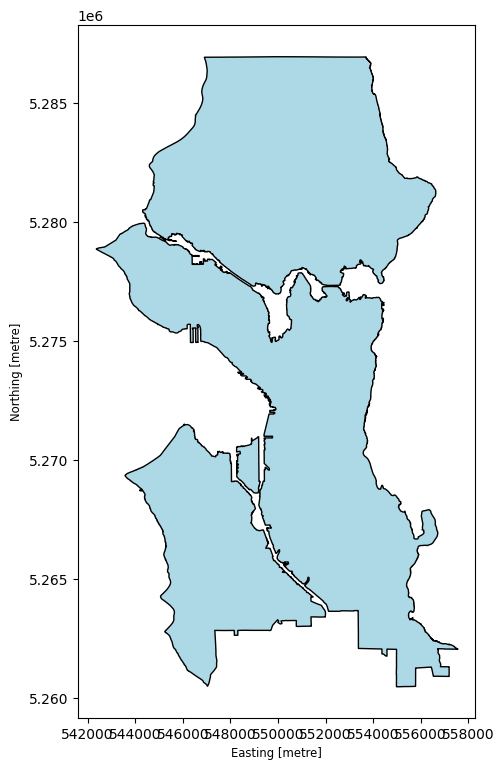

In [9]:
# Muestro el mapa sin las divisiones censales internas.
seattle.plot(
    figsize=(7, 9),
    color="lightblue",
    edgecolor="black"
)


## Preparación de los datos de OpenStreetMap
### Estaciones de gasolina

Obtengo las estaciones de gasolina de Seattle mediante OSMnx y reviso sus datos y su sistema de coordenadas.



In [10]:
import osmnx as ox

# Obtengo las estaciones de gasolina de Seattle.
stations = ox.features_from_place(
    "Seattle, Washington, USA",
    tags={"amenity": "fuel"}
)

In [11]:
# Reviso la información de las estaciones descargadas.
stations.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 128 entries, ('node', np.int64(457773031)) to ('way', np.int64(1460417274))
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   geometry                   128 non-null    geometry
 1   amenity                    128 non-null    object  
 2   brand                      111 non-null    object  
 3   brand:wikidata             109 non-null    object  
 4   name                       122 non-null    object  
 5   addr:city                  47 non-null     object  
 6   addr:housenumber           51 non-null     object  
 7   addr:postcode              46 non-null     object  
 8   addr:street                51 non-null     object  
 9   check_date                 65 non-null     object  
 10  compressed_air             60 non-null     object  
 11  opening_hours              51 non-null     object  
 12  website                    49 

In [12]:
# Identifico el sistema de coordenadas de los datos.
stations.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [13]:
# Muestro los datos de las estaciones de gasolina.
stations

geometry amenity  \
element id                                                                      
node    457773031                         POINT (-122.39997 47.63939)    fuel   
        631386821                          POINT (-122.3203 47.62518)    fuel   
        771801423                         POINT (-122.35525 47.73205)    fuel   
        1197964284                        POINT (-122.32958 47.58001)    fuel   
        1489962206                        POINT (-122.32805 47.66483)    fuel   
...                                                               ...     ...   
way     684913608   POLYGON ((-122.37612 47.5448, -122.37623 47.54...    fuel   
        727276570   POLYGON ((-122.33603 47.53219, -122.33603 47.5...    fuel   
        940949039   POLYGON ((-122.26383 47.68144, -122.26394 47.6...    fuel   
        1106778201  POLYGON ((-122.30916 47.57672, -122.30956 47.5...    fuel   
        1460417274  POLYGON ((-122.29762 47.5779, -122.29746 47.57...    fuel   

                       brand brand:wikidata                          name  \
element id                                                                  
node    457773031    Chevron        Q319642              Magnolia Chevron   
        631386821         76       Q1658320                            76   
        771801423    Chevron        Q319642                       Chevron   
        1197964284     Shell     Q110716465                         Shell   
        1489962206  7-Eleven        Q259340                      7-Eleven   
...                      ...            ...                           ...   
way     684913608        NaN            NaN  Gasco & South Seattle Market   
        727276570      Shell     Q110716465                       Shree's   
        940949039   7-Eleven        Q259340                      7-Eleven   
        1106778201  Sinclair            NaN                           NaN   
        1460417274      Arco        Q304769                          Arco   

                   addr:city addr:housenumber addr:postcode  \
element id                                                    
node    457773031        NaN              NaN           NaN   
        631386821    Seattle              915         98102   
        771801423        NaN              NaN           NaN   
        1197964284       NaN              NaN           NaN   
        1489962206       NaN              NaN           NaN   
...                      ...              ...           ...   
way     684913608        NaN              NaN           NaN   
        727276570    Seattle              140         98106   
        940949039        NaN              NaN           NaN   
        1106778201       NaN              NaN           NaN   
        1460417274       NaN              NaN           NaN   

                                addr:street  check_date  ... start_date  \
element id                                               ...              
node    457773031                       NaN         NaN  ...        NaN   
        631386821           East Roy Street  2024-08-13  ...        NaN   
        771801423                       NaN         NaN  ...        NaN   
        1197964284                      NaN         NaN  ...        NaN   
        1489962206                      NaN  2026-02-18  ...        NaN   
...                                     ...         ...  ...        ...   
way     684913608                       NaN         NaN  ...        NaN   
        727276570   Southwest Kenyon Street         NaN  ...        NaN   
        940949039                       NaN         NaN  ...        NaN   
        1106778201                      NaN         NaN  ...        NaN   
        1460417274                      NaN         NaN  ...        NaN   

                   fuel:e85 maxheight contact:facebook contact:instagram  \
element id                                                                 
node    457773031       NaN       NaN              NaN   

In [14]:
# Reviso el tipo de elemento y su identificador en OpenStreetMap.
stations.index

MultiIndex([('node',  457773031),
            ('node',  631386821),
            ('node',  771801423),
            ('node', 1197964284),
            ('node', 1489962206),
            ('node', 2266423106),
            ('node', 2702032640),
            ('node', 2702054487),
            ('node', 2995124967),
            ('node', 5283345524),
            ...
            ( 'way',  600101678),
            ( 'way',  600101691),
            ( 'way',  600101760),
            ( 'way',  603557992),
            ( 'way',  616232144),
            ( 'way',  684913608),
            ( 'way',  727276570),
            ( 'way',  940949039),
            ( 'way', 1106778201),
            ( 'way', 1460417274)],
           names=['element', 'id'], length=128)

In [15]:
# Convierto el tipo de elemento y su identificador en columnas.
stations.reset_index(drop=False, inplace=True)

# Muestro las primeras cinco filas.
stations.head()

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source
0,node,457773031,POINT (-122.39997 47.63939),fuel,Chevron,Q319642,Magnolia Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,node,631386821,POINT (-122.3203 47.62518),fuel,76,Q1658320,76,Seattle,915,98102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,node,771801423,POINT (-122.35525 47.73205),fuel,Chevron,Q319642,Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,node,1197964284,POINT (-122.32958 47.58001),fuel,Shell,Q110716465,Shell,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,node,1489962206,POINT (-122.32805 47.66483),fuel,7-Eleven,Q259340,7-Eleven,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
# Conservo el tipo de elemento, el nombre y la geometría.
colsToKeep = ["element", "name", "geometry"]
fuelSeattle = stations[colsToKeep].copy()

In [17]:
# Uso el mismo sistema de coordenadas del mapa de Seattle.
fuelSeattle = fuelSeattle.to_crs(Seattle_crs)

In [18]:
# Reviso las columnas y los datos disponibles.
fuelSeattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   element   128 non-null    object  
 1   name      122 non-null    object  
 2   geometry  128 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 3.1+ KB


In [19]:
# Reemplazo los nombres faltantes por "Sin nombre".
# Así conservo los registros aunque OpenStreetMap no indique su nombre.
fuelSeattle.fillna({"name": "Sin nombre"}, inplace=True)

In [20]:
# Combino el número de cada fila con el nombre de la estación.
# El número permite distinguir registros que tienen el mismo nombre.
# Esta línea solo muestra el resultado; todavía no lo guarda.
fuelSeattle.index.astype(str) + "_" + fuelSeattle["name"]

,0
0,0_Magnolia Chevron
1,1_76
2,2_Chevron
3,3_Shell
4,4_7-Eleven
...,...
123,123_Gasco & South Seattle Market
124,124_Shree's
125,125_7-Eleven
126,126_Sin nombre


In [21]:
# Creo la columna newname con un identificador para cada registro.
fuelSeattle["newname"] = (
    fuelSeattle.index.astype(str) + "_" + fuelSeattle["name"]
)

# Uso ese identificador como índice, es decir, como etiqueta de cada fila.
fuelSeattle.set_index("newname", inplace=True)

# Elimino la columna name porque su contenido ya está incluido en el índice.
fuelSeattle.drop(columns=["name"], inplace=True)

# Muestro las primeras cinco filas para revisar el resultado.
fuelSeattle.head()

,element,geometry
newname,,
0_Magnolia Chevron,node,POINT (545070.577 5276395.041)
1_76,node,POINT (551068.412 5274865.552)
2_Chevron,node,POINT (548343.649 5286720.849)
3_Shell,node,POINT (550414.847 5269839.108)
4_7-Eleven,node,POINT (550448.153 5279266.856)


In [22]:
# Importo pandas, una biblioteca para trabajar con tablas.
import pandas as pd

# Comparo el tipo de elemento de OpenStreetMap (element)
# con su tipo de geometría (Point, Polygon, etc.).
# Cada casilla muestra cuántos registros tienen esa combinación.
# margins=True agrega una fila y una columna All con los totales.
pd.crosstab(
    fuelSeattle["element"],
    fuelSeattle.geometry.geom_type,
    margins=True
)

col_0,Point,Polygon,All
element,,,
node,17,0,17
way,0,111,111
All,17,111,128


In [28]:
# La descarga contiene 128 registros: 17 puntos y 111 polígonos.
# No aparecen elementos de tipo relation, por lo que omito
# la inspección y el gráfico de relation del ejemplo del profesor.

In [30]:
# Descargo de OpenStreetMap los elementos de Seattle
# etiquetados como amenity=school (colegios).
# Esta consulta no incluye automáticamente universidades ni jardines infantiles.
schools = ox.features_from_place(
    "Seattle, Washington, USA",
    tags={"amenity": "school"}
)

# Reviso cuántos registros se descargaron, sus columnas
# y cuántos valores disponibles tiene cada columna.
schools.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 217 entries, ('node', np.int64(356540545)) to ('way', np.int64(1547977369))
Data columns (total 74 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   geometry                 217 non-null    geometry
 1   amenity                  217 non-null    object  
 2   check_date               26 non-null     object  
 3   ele                      140 non-null    object  
 4   gnis:feature_id          146 non-null    object  
 5   name                     215 non-null    object  
 6   addr:city                158 non-null    object  
 7   addr:housenumber         166 non-null    object  
 8   addr:postcode            157 non-null    object  
 9   addr:street              166 non-null    object  
 10  opening_hours            36 non-null     object  
 11  website                  111 non-null    object  
 12  religion                 25 non-null     object  
 13  nam

In [31]:
# Convierto el tipo de elemento y su identificador de OpenStreetMap
# en columnas, dejando un índice numérico para las filas.
# Trabajo sobre una copia para conservar schools como descarga original.
schoolSeattle = schools.reset_index()

# Conservo el tipo de elemento, el nombre y la geometría.
schoolSeattle = schoolSeattle[["element", "name", "geometry"]].copy()

# Completo los nombres faltantes sin eliminar esos registros.
schoolSeattle.fillna({"name": "Sin nombre"}, inplace=True)

# Combino el número de fila y el nombre para crear etiquetas únicas,
# incluso cuando varios colegios tienen el mismo nombre.
schoolSeattle["newname"] = (
    schoolSeattle.index.astype(str) + "_" + schoolSeattle["name"]
)

# Uso las etiquetas creadas como índice de la tabla.
schoolSeattle.set_index("newname", inplace=True)

# Elimino name porque el nombre ya está incluido en el índice.
schoolSeattle.drop(columns=["name"], inplace=True)

# Transformo las coordenadas al mismo sistema de Seattle y las estaciones:
# EPSG:32610, cuyas unidades son metros.
# Así podré calcular distancias entre las geometrías.
schoolSeattle = schoolSeattle.to_crs(Seattle_crs)

# Muestro las primeras cinco filas para revisar el resultado.
schoolSeattle.head()

,element,geometry
newname,,
0_Mapleleaf School,node,POINT (552925.436 5283350.335)
1_Hazel Wolf K-8,node,POINT (550876.028 5280652.219)
2_Epic Life Academy,node,POINT (549394.116 5283758.769)
3_Christ the King Elementary School,node,POINT (548515.145 5284662.849)
4_Assumption Saint Bridget School,node,POINT (553072.046 5280365.741)


In [32]:
# Cuento los colegios según su tipo de elemento de OpenStreetMap
# y su geometría: Point, Polygon o MultiPolygon.
# Un MultiPolygon reúne varios polígonos en un mismo registro.
# margins=True agrega los totales.
pd.crosstab(
    schoolSeattle["element"],
    schoolSeattle.geometry.geom_type,
    margins=True
)

col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


,element,geometry
newname,,
54_Franklin High School,relation,"MULTIPOLYGON (((553161.198 5269473.122, 553170..."
56_Seattle Preparatory School,relation,"MULTIPOLYGON (((551241.808 5276761.858, 551251..."
57_Cascadia Elementary School,relation,"MULTIPOLYGON (((549699.038 5282610.148, 549699..."
59_Sand Point Elementary School,relation,"MULTIPOLYGON (((555274.247 5280320.317, 555274..."


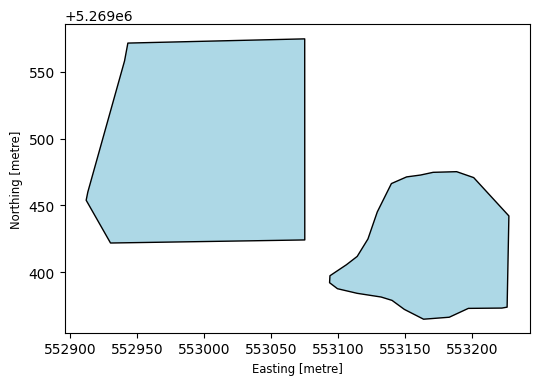

In [35]:
# Selecciono los colegios de tipo relation con geometría MultiPolygon.
colegios_multipoligono = schoolSeattle[
    (schoolSeattle["element"] == "relation")
    & (schoolSeattle.geometry.geom_type == "MultiPolygon")
]

# Muestro todos los registros que cumplen el filtro.
display(colegios_multipoligono)

# Grafico solo el primer colegio para observar sus partes en detalle.
# Al graficar los cuatro juntos, sus áreas parecen puntos
# porque están separadas por varios kilómetros.
if not colegios_multipoligono.empty:
    colegios_multipoligono.iloc[[0]].plot(
        figsize=(6, 6),
        color="lightblue",
        edgecolor="black"
    )
else:
    print("No hay colegios que cumplan este filtro.")

In [40]:
import folium

# Uso todo el ancho disponible en Colab y mantengo 700 píxeles de altura.
figura = folium.Figure(width="100%", height=700)

# Centro la vista en Seattle y establezco el acercamiento inicial.
# Mantengo el fondo neutro porque los anteriores mostraron bloqueos.
base = folium.Map(
    location=[47.60, -122.33],
    zoom_start=10,
    tiles=None,
    width="100%",
    height="100%",
    control_scale=True
)

# Coloco el mapa dentro del recuadro.
base.add_to(figura)

# Dibujo el límite de Seattle con un relleno celeste suave.
# fit_bounds=False evita que esta capa cambie el acercamiento elegido.
seattle.explore(
    m=base,
    color="#4b829e",
    name="Límite de Seattle",
    fit_bounds=False,
    style_kwds={"fillOpacity": 0.15, "weight": 2}
)

# Agrego todos los colegios en negro.
schoolSeattle.explore(
    m=base,
    color="black",
    name="Colegios",
    fit_bounds=False,
    marker_kwds={"radius": 3},
    style_kwds={"weight": 1, "fillOpacity": 0.6}
)

# Agrego todas las estaciones en rojo.
# Todavía no las clasifico por su distancia a los colegios.
fuelSeattle.explore(
    m=base,
    color="#d73027",
    name="Estaciones de gasolina",
    fit_bounds=False,
    marker_kwds={"radius": 4},
    style_kwds={"weight": 1, "fillOpacity": 0.7}
)

# Permito activar y desactivar las capas desde la esquina superior derecha.
folium.LayerControl(collapsed=False).add_to(base)

# Muestro el recuadro completo una sola vez.
display(figura)

In [41]:
# Calculo la distancia de cada estación a todas las estaciones.
# apply recorre las geometrías y lambda llama "station"
# a la geometría que estoy evaluando en cada paso.
# Obtengo una tabla con estaciones en las filas y en las columnas.
# Cada casilla contiene la distancia mínima entre sus geometrías.
# Las distancias están en metros porque uso EPSG:32610.
# Son distancias directas, no recorridos por calles.

D_Matrix_fuel_fuel = fuelSeattle.geometry.apply(
    lambda station: fuelSeattle.geometry.distance(station)
)

# Muestro la matriz de distancias.
# La diagonal contiene ceros porque compara cada estación consigo misma.
D_Matrix_fuel_fuel

newname,0_Magnolia Chevron,1_76,2_Chevron,3_Shell,4_7-Eleven,5_7-Eleven,6_Morrison's North Star Marine,7_Shilshole Fuel Dock,8_Dr. Dan's Biodiesel,9_76,...,118_Chevron,119_76,120_Chevron,121_Safeway Fuel Station,122_Shell,123_Gasco & South Seattle Market,124_Shree's,125_7-Eleven,126_Sin nombre,127_Arco
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,0.000000,6189.778099,10832.142979,8458.219249,6096.362935,3911.871820,4154.629544,4607.185893,3684.919842,6799.259673,...,11032.720301,8059.083730,8471.490011,11342.071122,8388.488702,10650.766388,12839.472695,11229.479609,9704.676294,10259.885224
1_76,6189.778099,0.000000,12164.390410,5068.756372,4444.794018,7396.837510,2913.822486,9025.058016,5776.876534,2146.281615,...,10502.171854,9283.591945,5828.349523,6582.987118,3490.937461,9859.853435,10391.001557,7544.714281,5423.572544,5486.468930
2_Chevron,10832.142979,12164.390410,0.000000,17008.322965,7745.382606,6939.794167,9680.781667,6982.575734,7498.129000,14199.195661,...,3434.731016,2961.691541,7436.375075,18706.121900,15655.292108,20857.745520,22251.515513,8863.786937,17578.604974,17632.751402
3_Shell,8458.219249,5068.756372,17008.322965,0.000000,9427.806838,11287.548358,7342.660400,12635.016000,9933.327452,2922.512744,...,15557.714940,14059.287367,10879.733945,3206.070889,2163.657924,5243.026228,5325.665547,12298.163104,1528.265114,2402.851126
4_7-Eleven,6096.362935,4444.794018,7745.382606,9427.806838,0.000000,4594.203464,2537.458079,6272.831613,3095.924539,6540.437675,...,6182.494529,4939.340577,2378.849213,10960.740771,7927.629559,13808.912707,14744.043923,5152.034055,9868.081904,9889.821437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,10650.766388,9859.853435,20857.745520,5243.026228,13808.912707,14330.734414,11384.887382,15256.296547,13384.622284,7840.707251,...,19975.906239,17895.800660,15622.732075,7048.807065,7406.644471,0.000000,3320.967459,17353.381510,6121.528764,6950.536820
124_Shree's,12839.472695,10391.001557,22251.515513,5325.665547,14744.043923,16185.514303,12571.965336,17343.197545,14990.551645,8245.361423,...,20883.253836,19286.809328,16183.027772,5393.694936,7165.874001,3320.967459,0.000000,17427.534450,5304.377123,5824.618469
125_7-Eleven,11229.479609,7544.714281,8863.786937,12298.163104,5152.034055,9340.534273,7314.479491,10839.148958,8108.038042,9514.437711,...,5617.194131,7342.966295,2828.590101,12564.668105,10253.850567,17353.381510,17427.534450,0.000000,12100.385190,11735.314154


In [42]:
# Creo una copia para conservar la matriz original.
distancias_otras_estaciones = D_Matrix_fuel_fuel.copy()

# Excluyo únicamente la comparación de cada estación consigo misma.
# NaN representa un valor ausente y no participa en el cálculo del mínimo.
# Conservo los ceros entre registros distintos, porque pueden indicar
# geometrías que se tocan, se superponen o representan el mismo lugar.
for estacion in distancias_otras_estaciones.index:
    distancias_otras_estaciones.loc[estacion, estacion] = float("nan")

# Busco el menor valor de cada fila:
# es la distancia de esa estación a la otra estación más cercana.
distancia_estacion_cercana = distancias_otras_estaciones.min(axis=1)

# Ordeno de menor a mayor y muestro los primeros diez resultados.
# Los valores están expresados en metros.
distancia_estacion_cercana.sort_values().head(10)

,0
newname,
3_Shell,0.000000
16_Chevron,0.000000
62_Shell,0.000000
114_University Chevron,0.000000
103_ARCO,3.577986
104_ARCO,3.577986
88_76,4.467367
89_76,4.467367
11_Chevron,9.231022


In [43]:
# Calculo la distancia de cada estación a todos los colegios.
# Cada fila representa una estación y cada columna representa un colegio.
# Cada casilla indica la distancia mínima entre sus geometrías, en metros.
# Conservo los puntos y polígonos originales: no los convierto en centroides.

D_Matrix_fuel_school = fuelSeattle.geometry.apply(
    lambda station: schoolSeattle.geometry.distance(station)
)

# Muestro la matriz que utilizaré para encontrar
# el colegio más cercano a cada estación.
# Aquí un cero es válido: indica que las geometrías se tocan o superponen.
# Todavía no clasifico las estaciones ni cambio los colores del mapa.
D_Matrix_fuel_school

newname,0_Mapleleaf School,1_Hazel Wolf K-8,2_Epic Life Academy,3_Christ the King Elementary School,4_Assumption Saint Bridget School,5_Saint Edward Parish School,6_Learning Way School,7_Concordia Lutheran School,8_Northwest Montessori School,9_Northwest Childrens Academy,...,207_Rainier Valley Leadership Academy,208_Eckstein Middle School,209_La Escuelita Bilingual School,210_Impact | Salish Sea Elementary,211_Little Laurels,212_Cascade Parent Partnership Program,213_Roxhill Elementary School,214_Downtown School,215_Seattle Waldorf School - Main Campus,216_Mercer International Middle School
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,10491.659688,7199.084975,8539.173303,8956.657111,8932.523151,13341.958719,13507.709663,9506.260725,4487.653029,5324.737909,...,13761.296382,9053.687052,7195.602311,14410.390399,12230.115714,3124.787461,13580.295215,4054.694024,10282.565861,10565.424327
1_76,8685.624613,5789.863861,9049.451299,10124.534305,5853.770242,8808.620825,11975.722628,6599.617370,5074.222149,880.126226,...,9194.797832,6402.592462,6089.745057,10238.137431,10878.978200,3673.708903,12398.535914,2554.619356,8612.096410,6727.699624
2_Chevron,5687.981663,6575.805111,3142.833012,2065.133147,7921.183151,20929.652730,23474.696332,7563.706626,7465.701803,11654.725826,...,21301.486962,7045.990100,6198.145060,22392.998311,4983.299677,9477.043229,23725.977819,12427.156563,5446.866034,18854.337587
3_Shell,13742.500324,10822.941478,13957.036131,14944.971496,10856.827909,4930.152593,6965.257592,11596.129786,9605.655199,5388.607746,...,5347.980500,11437.825204,11106.714608,5956.588399,15939.807496,7649.546886,7450.088356,4780.314108,13675.664902,2107.909975
4_7-Eleven,4776.163021,1449.933898,4613.922112,5731.776499,2844.708492,13184.453100,16181.746778,3413.989799,1921.307178,4045.349103,...,13557.409322,2975.949318,1688.226327,14650.612357,6843.922073,3022.474841,16531.995201,5311.494858,4626.744314,11169.644124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,18437.654830,15257.637660,18016.092365,18818.447391,15701.177153,7223.804112,2917.573907,16447.522259,13440.851728,9890.137026,...,7489.956010,16219.730566,15482.629187,7043.580298,20596.596877,11308.744575,2917.011727,8493.599402,18333.769196,5192.808772
124_Shree's,19046.714482,16146.376840,19238.321146,20186.490665,16131.338043,4633.509651,2212.511637,16863.752907,14799.205507,10699.306284,...,4762.577365,16729.265592,16426.505984,3973.425033,21246.496324,12755.913237,2957.170911,9823.178035,18986.753055,3812.301432
125_7-Eleven,3191.366019,4396.077208,6402.128582,7587.141782,2308.936140,14581.418422,19250.984757,1890.496999,6978.426106,7738.111508,...,14859.036606,2191.162884,4562.774267,16156.189878,4800.640849,8052.316222,19748.085148,9560.847169,3273.765496,13416.903822


## Decisión 1: Identificar las estaciones que no cumplen la distancia mínima

Calculo la distancia de cada estación de gasolina al colegio más cercano y ordeno los resultados. Para esta tarea, establezco una separación mínima de 200 metros.

In [44]:
# Busco el menor valor de cada fila de la matriz.
# Como cada fila es una estación y las columnas son colegios,
# obtengo la distancia de cada estación a su colegio más cercano.
# axis=1 indica que comparo los valores entre columnas.
distancia_colegio_cercano = D_Matrix_fuel_school.min(axis=1)

# Ordeno las distancias de menor a mayor.
# Muestro las diez estaciones que están más próximas a algún colegio.
# Los resultados están en metros.
distancia_colegio_cercano.sort_values().head(10)

,0
newname,
102_Shell,0.824760
38_Shell,23.258460
69_Shell,36.646314
1_76,75.072216
111_Space Age,91.233431
74_Shell,94.493039
109_Shell,97.053490
96_Chevron,100.324890
36_Chevron,112.051912


In [46]:
# Establezco la separación mínima exigida en esta tarea: 200 metros.
# Una estación a menos de 200 m de un colegio no cumple el criterio.
# Una estación a 200 m o más sí cumple este criterio de distancia.
# Este valor corresponde al ejercicio, no a una norma legal verificada.
mindDist = 200

## Decisión 2: Crear un área de protección alrededor de cada colegio

Creo un buffer de 200 metros alrededor de la geometría de cada colegio para representar su zona de proximidad.

In [47]:
# Creo un buffer de 200 metros alrededor de la geometría de cada colegio.
# Si el colegio es un punto, el buffer forma un área aproximadamente circular.
# Si es un polígono, el área se extiende 200 metros desde su contorno.
# Así represento espacialmente la zona de proximidad de cada colegio.
# Uso el sistema proyectado en metros que ya tiene schoolSeattle.
# Guardo el resultado aparte para conservar las geometrías originales.
schoolSeattle_buffered = schoolSeattle.buffer(mindDist)

# Muestro las geometrías de las áreas creadas.
schoolSeattle_buffered

,0
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


In [48]:
# Compruebo qué tipo de objeto produjo buffer.
# Una GeoSeries es una serie de geometrías con su índice
# y su sistema de coordenadas.
type(schoolSeattle_buffered)

geopandas.geoseries.GeoSeries

### Convertir las áreas de protección en una tabla geográfica

Organizo los buffers en un GeoDataFrame para utilizarlos en las siguientes operaciones espaciales.

In [49]:
# Convierto la GeoSeries en un GeoDataFrame:
# una tabla cuya columna geometry contiene las áreas creadas.
# Conservo los identificadores de los colegios como índice
# y el mismo sistema de coordenadas.
secured_schoolSeattle = gpd.GeoDataFrame(
    geometry=schoolSeattle_buffered,
    crs=schoolSeattle.crs
)

# Muestro la tabla de áreas de proximidad.
secured_schoolSeattle

,geometry
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


### Revisar las geometrías creadas

Cuento cuántos buffers son polígonos y cuántos son multipolígonos.

In [50]:
# Cuento cuántas áreas son Polygon y cuántas son MultiPolygon.
# Un buffer puede seguir siendo MultiPolygon si sus partes
# permanecen separadas después de ampliarlas.
# Por eso mis cantidades pueden diferir de las del profesor.
secured_schoolSeattle.geometry.geom_type.value_counts()

,count
Polygon,217


## Decisión 3: Estandarizar las geometrías de las estaciones de gasolina

Reviso las geometrías y preparo una copia donde las estaciones representadas como puntos se convierten en pequeñas áreas de 10 metros de radio.

In [51]:
# Cuento las estaciones según su geometría original.
# En mis datos había 17 puntos y 111 polígonos.
fuelSeattle.geometry.geom_type.value_counts()

,count
Polygon,111
Point,17


In [52]:
# Creo una copia para conservar las geometrías originales de fuelSeattle.
fuelSeattle_allPoly = fuelSeattle.copy()

# Recorro las geometrías de las estaciones.
# Si la geometría es un punto, creo un buffer de 10 metros de radio.
# Si ya es un polígono, lo conservo sin cambios.
# Estos círculos son una representación aproximada:
# no corresponden necesariamente al terreno real de la estación.
fuelSeattle_allPoly["geometry"] = [
    station.buffer(10) if station.geom_type == "Point" else station
    for station in fuelSeattle.geometry
]

# Compruebo que las 128 geometrías ahora sean polígonos.
fuelSeattle_allPoly.geometry.geom_type.value_counts()

,count
Polygon,128


## Decisión 4: Comparar la intersección y la unión espacial

Comparo dos operaciones: overlay obtiene las partes de las estaciones que coinciden con los buffers escolares; sjoin identifica las coincidencias conservando la geometría completa de cada estación.

In [53]:
# Obtengo las partes de las estaciones que se superponen
# con las áreas de 200 metros alrededor de los colegios.
# how="intersection" conserva solamente las partes compartidas.
# keep_geom_type=False permite conservar también contactos
# que produzcan líneas o puntos.
intersecciones = fuelSeattle_allPoly.overlay(
    secured_schoolSeattle,
    how="intersection",
    keep_geom_type=False
)

# Muestro las geometrías recortadas por la intersección.
# Una estación puede aparecer varias veces si coincide
# con los buffers de varios colegios.
intersecciones

,element,geometry
0,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
1,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
2,node,"POLYGON ((550424.799 5269838.128, 550424.655 5..."
3,node,"POLYGON ((545961.026 5280205.552, 545960.882 5..."
4,node,"POLYGON ((553782.981 5266125.595, 553782.837 5..."
5,node,"POLYGON ((548171.127 5263444.827, 548170.983 5..."
6,way,"POLYGON ((549200.164 5283742.752, 549194.91 52..."
7,way,"POLYGON ((546272.901 5269904.828, 546264.427 5..."
8,way,"POLYGON ((552390.26 5272921.863, 552382.489 52..."
9,way,"POLYGON ((552390.26 5272921.863, 552382.489 52..."


In [54]:
# Identifico las estaciones que intersectan los buffers escolares.
# how="inner" conserva únicamente los registros con coincidencias.
# predicate="intersects" incluye superposiciones y contactos en los bordes.
# A diferencia de overlay, sjoin conserva la geometría completa
# de la estación en esta copia.
coincidencias = fuelSeattle_allPoly.sjoin(
    secured_schoolSeattle,
    how="inner",
    predicate="intersects"
)

# Muestro las estaciones junto al identificador del colegio relacionado.
# Una estación puede repetirse si coincide con varios colegios.
# Por eso el número de filas no equivale necesariamente
# al número de estaciones diferentes.
coincidencias

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.808, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School


### Interpretación de las coincidencias

Estas operaciones permiten explorar las superposiciones. Sin embargo, el buffer adicional de 10 metros amplía las estaciones que originalmente eran puntos y puede generar coincidencias incluso cuando su distancia original al colegio es mayor de 200 metros.

Por ello, para decidir cuáles incumplen el criterio de la tarea, utilizaré la distancia calculada con las geometrías originales: menos de 200 metros.

### Revisar las estaciones repetidas en la unión espacial

Una estación puede aparecer varias veces porque coincide con las áreas de protección de varios colegios. Reviso estas repeticiones antes de contar las estaciones.

In [55]:
# Identifico todas las filas cuyo identificador de estación se repite.
# keep=False marca todas las apariciones de cada identificador repetido.
is_duplicate = coincidencias.index.duplicated(keep=False)

# Muestro las estaciones repetidas y sus colegios relacionados.
# Si la tabla está vacía, no hay identificadores repetidos.
coincidencias[is_duplicate]

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",187_Nova High School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",198_Seattle World School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",116_Morningside Academy
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",51_The Hatch School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",198_Seattle World School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",116_Morningside Academy


### Conservar una coincidencia por estación

Elimino las repeticiones producidas por la unión espacial. Esto evita contar varias veces una estación que coincide con diferentes colegios.

In [63]:
# Conservo la primera aparición de cada identificador.
# El símbolo ~ invierte la condición: selecciono las filas no repetidas.
# Es una forma más directa de hacer la limpieza del profesor.
coincidencias_unicas = coincidencias.loc[
    ~coincidencias.index.duplicated(keep="first")
].copy()

# El colegio conservado es la primera coincidencia encontrada;
# no necesariamente es el colegio más cercano.
# Esta limpieza solo elimina repeticiones del mismo identificador.
coincidencias_unicas

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.808, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
34_Chevron,way,"POLYGON ((546913.57 5282556.957, 546902.092 52...",199_Whitman Middle School


### Seleccionar las estaciones que requieren reubicación

Aplico el criterio de la tarea: selecciono las estaciones cuya distancia al colegio más cercano es menor de 200 metros. Utilizo las geometrías originales para que el buffer adicional de 10 metros no altere la clasificación.

In [66]:
# Obtengo la distancia de cada estación al colegio más cercano.
distancia_colegio_cercano = D_Matrix_fuel_school.min(axis=1)

# Selecciono las estaciones que incumplen la distancia mínima de 200 m.
mindDist = 200
gas_relocate = fuelSeattle.loc[
    distancia_colegio_cercano < mindDist
].copy()

# Agrego la distancia para revisar el resultado.
gas_relocate["distancia_colegio_m"] = distancia_colegio_cercano

# Muestro la cantidad y ordeno desde la estación más cercana a un colegio.
print(f"Estaciones que requieren reubicación: {len(gas_relocate)}")
gas_relocate.sort_values("distancia_colegio_m")

Estaciones que requieren reubicación: 26


,element,geometry,distancia_colegio_m
newname,,,
102_Shell,way,"POLYGON ((553695.69 5268093.601, 553696.115 52...",0.824760
38_Shell,way,"POLYGON ((552492.588 5281287.156, 552497.278 5...",23.258460
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",36.646314
1_76,node,POINT (551068.412 5274865.552),75.072216
111_Space Age,way,"POLYGON ((546952.56 5264716.416, 546952.5 5264...",91.233431
74_Shell,way,"POLYGON ((546572.207 5267736.989, 546560.95 52...",94.493039
109_Shell,way,"POLYGON ((549608.081 5278917.657, 549608.477 5...",97.053490
96_Chevron,way,"POLYGON ((546117.77 5269973.976, 546117.607 52...",100.324890
36_Chevron,way,"POLYGON ((553264.062 5281139.909, 553263.714 5...",112.051912


### Visualizar las estaciones seleccionadas y los buffers escolares

Represento en rojo las estaciones que requieren reubicación y en amarillo las áreas de protección de los colegios relacionados. El contorno de Seattle permite ubicar los resultados.

In [67]:
import folium
from IPython.display import display

# Selecciono los colegios a menos de 200 m de alguna estación seleccionada.
colegios_relacionados = (
    D_Matrix_fuel_school.loc[gas_relocate.index] < mindDist
).any(axis=0)

buffers_relacionados = secured_schoolSeattle.loc[
    colegios_relacionados[colegios_relacionados].index
]

# Creo un mapa que ocupa todo el ancho, sin el fondo que dio errores.
figura = folium.Figure(width="100%", height=700)
base = folium.Map(
    location=[47.60, -122.33], zoom_start=11,
    tiles=None, width="100%", height="100%"
)
base.add_to(figura)

# Dibujo el límite de Seattle, los buffers amarillos y las estaciones rojas.
seattle.explore(
    m=base, color="steelblue", fit_bounds=False,
    style_kwds={"fillOpacity": 0, "weight": 2}
)
buffers_relacionados.explore(m=base, color="yellow", fit_bounds=False)
gas_relocate.explore(m=base, color="red", fit_bounds=False)

# Ajusto la vista para mostrar Seattle completo.
oeste, sur, este, norte = seattle.to_crs("EPSG:4326").total_bounds
base.fit_bounds([[sur, oeste], [norte, este]])
display(figura)

### Decisión 5: Buscar posibles lugares para reubicar las estaciones

In [68]:
# Descargo las vías transitables en vehículo de Seattle.
place = "Seattle, Washington, USA"
G = ox.graph_from_place(place, network_type="drive")

# Convierto los tramos de las vías en una tabla geográfica.
streets = ox.graph_to_gdfs(G, nodes=False, edges=True)
streets.shape

(50301, 15)

In [69]:
# Reviso las columnas y los datos disponibles.
streets.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 50301 entries, (np.int64(29445663), np.int64(29485641), np.int64(0)) to (np.int64(14237930653), np.int64(53073730), np.int64(0))
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   osmid     50301 non-null  object  
 1   highway   50301 non-null  object  
 2   lanes     38813 non-null  object  
 3   maxspeed  49897 non-null  object  
 4   oneway    50301 non-null  bool    
 5   ref       749 non-null    object  
 6   reversed  50301 non-null  object  
 7   length    50301 non-null  float64 
 8   geometry  50301 non-null  geometry
 9   bridge    484 non-null    object  
 10  name      44926 non-null  object  
 11  tunnel    59 non-null     object  
 12  junction  4742 non-null   object  
 13  access    237 non-null    object  
 14  width     270 non-null    object  
dtypes: bool(1), float64(1), geometry(1), object(12)
memory usage: 7.0+ MB


### Revisar los tipos de vías

In [70]:
# Separo las categorías de los tramos que tienen más de un tipo de vía.
streets["highway"].explode().value_counts()

,count
highway,
residential,35184
tertiary,5473
secondary,4787
primary,2825
unclassified,1025
motorway_link,294
trunk,252
motorway,177
primary_link,157


### Seleccionar las vías consideradas en el ejercicio

In [73]:
# Uso las categorías principales y sus conexiones, como en el ejemplo.
GAS_STATION_ROAD_TYPES = [
    "motorway", "primary", "trunk",
    "motorway_link", "primary_link", "trunk_link"
]

# Incluyo los tramos que tienen al menos una categoría seleccionada.
seleccion = streets["highway"].apply(
    lambda tipos: any(t in GAS_STATION_ROAD_TYPES for t in tipos)
    if isinstance(tipos, list) else tipos in GAS_STATION_ROAD_TYPES
)
suitable_roads = streets.loc[seleccion].copy()

# Muestro la cantidad de tramos y columnas.
suitable_roads.shape

(3723, 15)

### Transformar las coordenadas de las vías

In [74]:
# Uso el mismo sistema de Seattle para trabajar en metros.
suitable_roads = suitable_roads.to_crs(seattle.crs)

### Crear áreas de separación alrededor de las estaciones

In [75]:
# Adopto los 100 m de separación del ejemplo del profesor.
competitionDistance = 100
fuelSeattle_allPoly_buffered = fuelSeattle_allPoly.buffer(competitionDistance)

# Reviso el tipo de objeto obtenido.
type(fuelSeattle_allPoly_buffered)

geopandas.geoseries.GeoSeries

In [76]:
# Convierto los buffers en una tabla geográfica.
secured_fuelSeattle_allPoly = gpd.GeoDataFrame(
    geometry=fuelSeattle_allPoly_buffered,
    crs=fuelSeattle_allPoly.crs
)

### Unir las áreas de exclusión de colegios y estaciones

In [77]:
# Uno los buffers escolares y los de las estaciones.
secured_areas_dissolved = secured_fuelSeattle_allPoly.overlay(
    secured_schoolSeattle, how="union", keep_geom_type=False
).dissolve()

# Conservo la geometría del área de exclusión.
secured_areas = secured_areas_dissolved[["geometry"]].copy()

### Visualizar los tramos dentro de las áreas de exclusión

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

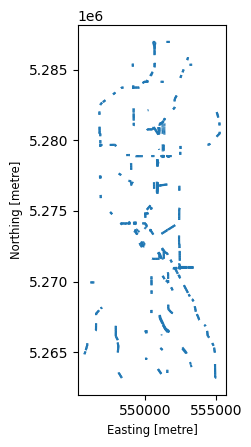

In [78]:
# Muestro los tramos dentro de los buffers: son zonas que debo excluir.
# clip conserva las partes interiores; todavía no obtiene las vías disponibles.
suitable_roads.clip(secured_areas, keep_geom_type=False).plot()

### Obtener los tramos fuera de las áreas de exclusión

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

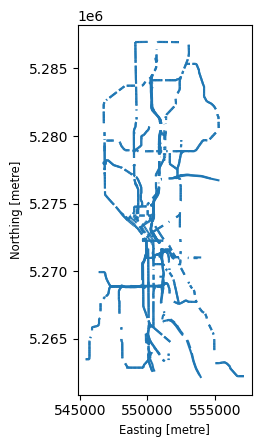

In [79]:
# Elimino las partes de las vías que atraviesan las áreas de exclusión.
tramos_disponibles = suitable_roads.overlay(
    secured_areas, how="difference", keep_geom_type=False
)

# Muestro los tramos restantes.
tramos_disponibles.plot()

### Comparar con la unión espacial

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

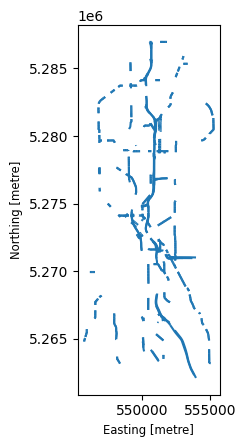

In [80]:
# Muestro los tramos completos que tocan las áreas de exclusión.
# sjoin identifica coincidencias, pero no recorta las vías.
suitable_roads.sjoin(
    secured_areas, how="inner", predicate="intersects"
).plot()

### Unir los tramos disponibles

In [81]:
# Conservo las líneas y las uno en un solo registro.
good_routes_forGas = tramos_disponibles.loc[
    tramos_disponibles.geom_type.isin(["LineString", "MultiLineString"]),
    ["geometry"]
].dissolve()

# Muestro la geometría donde buscaré nuevas ubicaciones.
good_routes_forGas

,geometry
0,"MULTILINESTRING ((551005.064 5276789.854, 5510..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

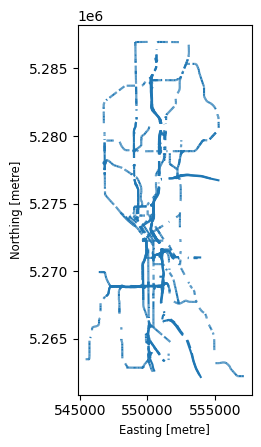

In [82]:
# Dibujo las vías disponibles para buscar las ubicaciones propuestas.
good_routes_forGas.plot()

### Generar ubicaciones propuestas sobre las vías

In [84]:
import numpy as np

# Limito la búsqueda a las vías dentro de Seattle.
potential_Locations = good_routes_forGas.clip(seattle)
newPOLYGONS = []
newPOINTS = []
attempts = 0

# Fijo la semilla para repetir el resultado.
rng = np.random.default_rng(42)

# Busco una propuesta por estación, con un límite de intentos.
while len(newPOINTS) < len(gas_relocate) and attempts < len(gas_relocate) * 100:

    if potential_Locations.empty or potential_Locations.length.sum() == 0:
        break

    attempts += 1

    # Genero dos puntos para evitar el error y tomo el primero.
    puntos = potential_Locations.sample_points(2, rng=rng)
    candidatePoint = puntos.explode(index_parts=False).iloc[0]

    # Creo el buffer alrededor del punto elegido.
    candidateBuffer = candidatePoint.buffer(competitionDistance)

    # Descarto buffers que toquen las áreas de exclusión.
    if secured_areas.intersects(candidateBuffer).any():
        continue

    # Compruebo la distancia a los colegios originales.
    if schoolSeattle.distance(candidatePoint).min() < mindDist:
        continue

    # Evito superponer los buffers de las nuevas propuestas.
    if any(candidateBuffer.intersects(area) for area in newPOLYGONS):
        continue

    # Guardo la ubicación y su buffer.
    newPOINTS.append(candidatePoint)
    newPOLYGONS.append(candidateBuffer)

# Muestro los intentos y las ubicaciones encontradas.
print(f"Intentos: {attempts}")
print(f"Ubicaciones propuestas: {len(newPOINTS)} de {len(gas_relocate)}")

Intentos: 35
Ubicaciones propuestas: 26 de 26


In [85]:
# Muestro los buffers de las nuevas ubicaciones.
newPOLYGONS

[<POLYGON ((550369.007 5273151.832, 550368.525 5273142.03, 550367.085 5273132...>,
 <POLYGON ((553636.968 5262937.722, 553636.486 5262927.92, 553635.046 5262918...>,
 <POLYGON ((550511.278 5274257.454, 550510.797 5274247.652, 550509.357 527423...>,
 <POLYGON ((547619.149 5268893.472, 547618.667 5268883.671, 547617.227 526887...>,
 <POLYGON ((550919.991 5268891.657, 550919.51 5268881.855, 550918.07 5268872....>,
 <POLYGON ((549832.529 5270750.487, 549832.048 5270740.685, 549830.608 527073...>,
 <POLYGON ((549425.6 5275879.038, 549425.118 5275869.236, 549423.678 5275859....>,
 <POLYGON ((550546.767 5265889.735, 550546.286 5265879.933, 550544.846 526587...>,
 <POLYGON ((552501.594 5265637.159, 552501.112 5265627.357, 552499.672 526561...>,
 <POLYGON ((548386.824 5268864.277, 548386.342 5268854.475, 548384.902 526884...>,
 <POLYGON ((550535.423 5268233.951, 550534.942 5268224.149, 550533.502 526821...>,
 <POLYGON ((550336.074 5272582.924, 550335.592 5272573.123, 550334.152 527256...>,
 <PO

In [87]:
# Muestro los buffers de las 26 ubicaciones propuestas.
gpd.GeoDataFrame(geometry=newPOLYGONS, crs=seattle.crs)

,geometry
0,"POLYGON ((550369.007 5273151.832, 550368.525 5..."
1,"POLYGON ((553636.968 5262937.722, 553636.486 5..."
2,"POLYGON ((550511.278 5274257.454, 550510.797 5..."
3,"POLYGON ((547619.149 5268893.472, 547618.667 5..."
4,"POLYGON ((550919.991 5268891.657, 550919.51 52..."
5,"POLYGON ((549832.529 5270750.487, 549832.048 5..."
6,"POLYGON ((549425.6 5275879.038, 549425.118 527..."
7,"POLYGON ((550546.767 5265889.735, 550546.286 5..."
8,"POLYGON ((552501.594 5265637.159, 552501.112 5..."
9,"POLYGON ((548386.824 5268864.277, 548386.342 5..."


In [88]:
# Guardo los buffers de las nuevas ubicaciones.
GoodLocationsGas_buffered_gdf = gpd.GeoDataFrame(geometry=newPOLYGONS, crs=seattle.crs)

# Obtengo los puntos centrales de cada buffer.
GoodLocationsGas_gdf = gpd.GeoDataFrame(geometry=GoodLocationsGas_buffered_gdf.centroid, crs=seattle.crs)

In [107]:
import folium
from branca.element import Element
from IPython.display import display

# Separo las gasolineras bien ubicadas.
gas_bien = fuelSeattle.drop(index=gas_relocate.index)

# Creo el mapa interactivo sin fondo.
figura = folium.Figure(width="100%", height=700)
base = folium.Map(
    location=[47.60, -122.33],
    zoom_start=11,
    tiles=None,
    width="100%",
    height="100%"
)
base.add_to(figura)

# Mantengo el fondo blanco.
figura.get_root().header.add_child(Element(
    "<style>.leaflet-container {background: white !important;}</style>"
))

# Dibujo el límite de Seattle.
seattle.explore(
    m=base, color="black", name="Límite de Seattle",
    fit_bounds=False, highlight=False,
    style_kwds={"fillOpacity": 0, "weight": 2}
)

# Muestro las vías disponibles en amarillo.
good_routes_forGas.clip(seattle).explore(
    m=base, color="yellow", name="Vías disponibles",
    fit_bounds=False, highlight=False
)

# Muestro los colegios en verde.
schoolSeattle.clip(seattle).explore(
    m=base, color="green", name="Colegios",
    fit_bounds=False, highlight=False
)

# Muestro las gasolineras bien ubicadas en negro.
gas_bien.clip(seattle).explore(
    m=base, color="black", name="Gasolineras bien ubicadas",
    fit_bounds=False, highlight=False
)

# Dibujo los buffers de las ubicaciones propuestas.
GoodLocationsGas_buffered_gdf.clip(seattle).explore(
    m=base, color="red", name="Buffers propuestos",
    fit_bounds=False, highlight=False,
    style_kwds={"fillOpacity": 0, "weight": 1}
)

# Marco las gasolineras mal ubicadas en rosado.
capa_rosada = folium.FeatureGroup(name="Gasolineras mal ubicadas")

for punto in gas_relocate.clip(seattle).to_crs(4326).geometry:
    centro = punto.centroid
    folium.CircleMarker(
        location=[centro.y, centro.x],
        radius=6,
        color="white",
        weight=1.5,
        fill=True,
        fill_color="#FF00B7",
        fill_opacity=1,
        tooltip="Gasolinera mal ubicada"
    ).add_to(capa_rosada)

capa_rosada.add_to(base)

# Marco las ubicaciones propuestas con cruces rojas pequeñas.
capa_propuestas = folium.FeatureGroup(name="Ubicaciones propuestas")

for i, punto in enumerate(GoodLocationsGas_gdf.clip(seattle).to_crs(4326).geometry):
    folium.Marker(
        location=[punto.y, punto.x],
        icon=folium.DivIcon(
            icon_size=(16, 16),
            icon_anchor=(8, 8),
            html="""
            <div style="
                font-size: 13px;
                font-weight: bold;
                color: red;
                text-align: center;
                line-height: 16px;
            ">✚</div>
            """
        ),
        tooltip=f"Ubicación propuesta {i+1}"
    ).add_to(capa_propuestas)

capa_propuestas.add_to(base)

# Ajusto el mapa al límite de Seattle.
oeste, sur, este, norte = seattle.to_crs(4326).total_bounds
base.fit_bounds([[sur, oeste], [norte, este]])

# Agrego el control de capas.
folium.LayerControl(collapsed=False).add_to(base)

# Agrego la leyenda al lado derecho.
leyenda = """
<div style="
    position: fixed;
    bottom: 30px;
    right: 20px;
    background: white;
    padding: 12px;
    border: 2px solid gray;
    border-radius: 8px;
    z-index: 9999;
    font-size: 13px;
    color: black;
    line-height: 24px;
">
<b>Leyenda - Seattle</b><hr>
<span style="color:black;">●</span> Gasolineras bien ubicadas<br>
<span style="color:#FF00B7;">●</span> Gasolineras mal ubicadas<br>
<span style="color:green;">●</span> Centros educativos<br>
<span style="color:red;">✚</span> Ubicaciones propuestas<br>
<span style="color:red;">◯</span> Buffers propuestos<br>
<span style="color:#d4b900;">━━━━</span> Vías disponibles<br>
<span style="color:black;">━━━━</span> Límite de Seattle
</div>
"""

figura.get_root().html.add_child(Element(leyenda))

# Muestro el mapa final.
display(figura)

## Geocodificación inversa (Reverse geocoding)

In [91]:
from geopy.geocoders import Nominatim
import time

# Inicializo el geocodificador para Seattle.
geolocator = Nominatim(user_agent="seattle_gas_stations")

# Obtengo la dirección de cada punto.
def get_address(point):
    lon = point.x
    lat = point.y

    location = geolocator.reverse((lat, lon), exactly_one=True, timeout=10)
    time.sleep(1)  # Evito consultas demasiado rápidas.

    if location:
        return location.address
    else:
        return None  # No se encontró la dirección.

In [93]:
# Convierto las nuevas ubicaciones a coordenadas geográficas.
GoodLocationsGas_4326 = GoodLocationsGas_gdf.to_crs('EPSG:4326')

# Obtengo las direcciones de las ubicaciones propuestas en Seattle.
GoodLocationsGas_gdf['address'] = GoodLocationsGas_4326.geometry.apply(get_address)


In [94]:
# Muestro las nuevas ubicaciones de Seattle con sus direcciones.
GoodLocationsGas_gdf

,geometry,address
0,POINT (550269.007 5273151.832),"I 5 Express, Central Business District, First ..."
1,POINT (553536.968 5262937.722),"I 5, South Beacon Hill, Seattle, King County, ..."
2,POINT (550411.278 5274257.454),"Eastlake Avenue East, South Lake Union, Cascad..."
3,POINT (547519.149 5268893.472),"Alki Trail, West Seattle, Seattle, King County..."
4,POINT (550819.991 5268891.657),"South Spokane Street, South Seattle, Seattle, ..."
5,POINT (549732.529 5270750.487),"1727, Alaskan Way South, Yesler Terrace, Seatt..."
6,POINT (549325.6 5275879.038),"1650, Aurora Avenue North, Westlake, Cascade, ..."
7,POINT (550446.767 5265889.735),"6519, 4th Avenue South, Van Asselt, Georgetown..."
8,POINT (552401.594 5265637.159),"I 5, Van Asselt, South Seattle, Seattle, King ..."
9,POINT (548286.824 5268864.277),"Southwest Spokane Street, Seattle, King County..."
